In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

PRED_DIR = "../results/predictions/tfidf"


from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score
from sklearn.metrics import precision_score, recall_score, f1_score

In [2]:
MAIN_IDENTITIES = [
    "male", "female", "homosexual_gay_or_lesbian", "christian", "jewish",
    "muslim", "black", "white", "psychiatric_or_mental_illness",
]

# TF-IDF with Logistic Regression

This notebook trains a linear baseline on TF-IDF features. Each comment is represented by the weight of its words and two-word expressions, and a logistic regression learns one coefficient per term.

**The coefficients show which words push a comment towards the toxic class.**



# 1. Load Data


In [3]:
DATA_PATH = "../data/processed/jigsaw_clean.parquet"

df = pd.read_parquet(DATA_PATH, columns=["id", "comment_text", "label", "split"] + MAIN_IDENTITIES)

train = df[df["split"] == "train"].reset_index(drop=True)
val = df[df["split"] == "validation"].reset_index(drop=True)
test = df[df["split"] == "test"].reset_index(drop=True)
del df

for name, part in [("Train", train), ("Validation", val), ("Test", test)]:
    print(f"{name}: {len(part):,} comments, toxic {part['label'].mean() * 100:.2f}%")


Train: 1,421,077 comments, toxic 7.98%
Validation: 177,637 comments, toxic 7.99%
Test: 177,635 comments, toxic 7.98%


# 2. Features

Build a TF-IDF matrix from unigrams and bigrams. The vocabulary and the IDF weights are learned on the training set only.

Each comment becomes a row of the matrix and each column is one term from the vocabulary. Bigrams are pairs of consecutive words, and each pair gets its own column, so word order is partly preserved.

For example, take two training comments:

- "you are bad" (toxic)
- "you are not bad" (non-toxic)

Their terms are:

- "you are bad": *you*, *are*, *bad*, *you are*, *are bad*
- "you are not bad": *you*, *are*, *not*, *bad*, *you are*, *are not*, *not bad*

The column *are bad* appears only in the toxic comment, and *not bad* only in the non-toxic one. The model can therefore give *not bad* a different weight from *bad*, which a single-word column cannot do.

In [4]:
vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=5, max_features=200_000, dtype="float32")

X_train = vectorizer.fit_transform(train["comment_text"])   # vocabulary and IDF learned on train only
X_val = vectorizer.transform(val["comment_text"])
X_test = vectorizer.transform(test["comment_text"])

y_train, y_val, y_test = train["label"], val["label"], test["label"]

print(f"Vocabulary size: {len(vectorizer.vocabulary_):,}")
print(f"Train matrix: {X_train.shape}")


/home/mar/miniconda3/envs/toxic-mod/lib/python3.12/site-packages/sklearn/feature_extraction/text.py:2049: UserWarning: Only (<class 'numpy.float64'>, <class 'numpy.float32'>, <class 'numpy.float16'>) 'dtype' should be used. float32 'dtype' will be converted to np.float64.
  warnings.warn(


Vocabulary size: 200,000
Train matrix: (1421077, 200000)


# 3. Logistic Regression

Train a logistic regression for several values of the regularization strength C. 

- Small C: the penalty on large weights is strong, so the model avoids large weights and overfitting.

- Large C: the training error weighs more, so the model fits the training data closely and its weights grow.

In [5]:
results = []
for C in [0.01, 0.1, 1, 10,30,50,60,70]:
    clf = LogisticRegression(C=C, max_iter=1000)
    clf.fit(X_train, y_train)


    train_pr = average_precision_score(y_train, clf.predict_proba(X_train)[:, 1])
    val_pr = average_precision_score(y_val, clf.predict_proba(X_val)[:, 1])
    results.append({"C": C, "train PR-AUC": train_pr, "validation PR-AUC": val_pr, "gap": train_pr - val_pr})

results = pd.DataFrame(results)
best_C = results.loc[results["validation PR-AUC"].idxmax(), "C"]
print(f"Selected C: {best_C}")
results

Selected C: 30.0


,C,train PR-AUC,validation PR-AUC,gap
0,0.01,0.487781,0.485679,0.002103
1,0.10,0.649353,0.639143,0.010210
2,1.00,0.742078,0.706035,0.036043
3,10.00,0.750741,0.707709,0.043032
4,30.00,0.763615,0.711834,0.051781
5,50.00,0.768298,0.709274,0.059025
6,60.00,0.777082,0.705381,0.071700
7,70.00,0.790970,0.704352,0.086618


The final model is retrained on the training set with the selected C.

 A comment is marked as toxic when its predicted probability is at least 0.5.


In [6]:
final_clf = LogisticRegression(C=best_C, max_iter=1000)
final_clf.fit(X_train, y_train)

test["prob_toxic"] = final_clf.predict_proba(X_test)[:, 1]
test["pred"] = (test["prob_toxic"] >= 0.5).astype(int)

print(f"Test PR-AUC: {average_precision_score(y_test, test['prob_toxic']):.3f}")
print(f"Comments marked as toxic: {test['pred'].sum():,} ({test['pred'].mean() * 100:.2f}%)")


Test PR-AUC: 0.687
Comments marked as toxic: 10,298 (5.80%)


# 4. Evaluation

Evaluate the selected model once on the test set, with the same metrics and tables used for the other models.

## 4.1 Confusion Matrix

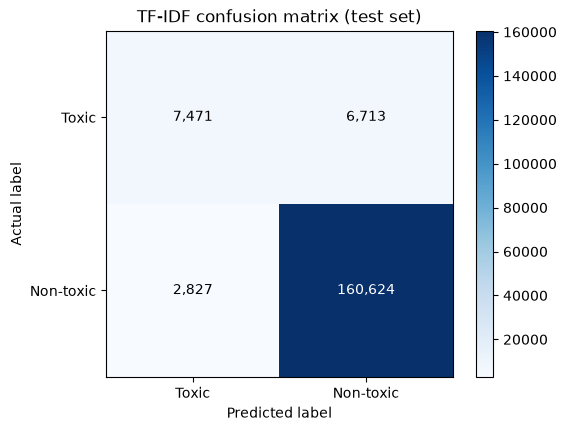

In [7]:
order = [1, 0]  # toxic first
counts = pd.crosstab(test["label"], test["pred"]).reindex(index=order, columns=order, fill_value=0)

fig, ax = plt.subplots(figsize=(6, 4.5))
im = ax.imshow(counts, cmap="Blues")
fig.colorbar(im, ax=ax)
for (i, j), n in np.ndenumerate(counts.values):
    ax.text(j, i, f"{n:,}", ha="center", va="center", color="white" if n > counts.values.max() / 2 else "black")
ax.set_xticks([0, 1], ["Toxic", "Non-toxic"])
ax.set_yticks([0, 1], ["Toxic", "Non-toxic"])
ax.set_xlabel("Predicted label")
ax.set_ylabel("Actual label")
ax.set_title("TF-IDF confusion matrix (test set)")
plt.show()

## 4.2 Precision, Recall and F1

In [8]:
y_pred = test["pred"]

metrics = pd.Series({
    "precision": precision_score(y_test, y_pred),
    "recall": recall_score(y_test, y_pred),
    "f1": f1_score(y_test, y_pred),
    "fpr": ((y_pred == 1) & (y_test == 0)).sum() / (y_test == 0).sum(),
    "fnr": ((y_pred == 0) & (y_test == 1)).sum() / (y_test == 1).sum(),
    "pr_auc": average_precision_score(y_test, test["prob_toxic"]),
}).round(3)
metrics


precision    0.725
recall       0.527
f1           0.610
fpr          0.017
fnr          0.473
pr_auc       0.687
dtype: float64

## 4.3 Results by Identity Subgroup

In [9]:
def group_metrics(mask):
    y_true, y_pred = test.loc[mask, "label"], test.loc[mask, "pred"]
    return {
        "comments": int(mask.sum()),
        "toxic": int(y_true.sum()),
        "acc toxic": ((y_pred == 1) & (y_true == 1)).sum() / (y_true == 1).sum(),
        "acc non-toxic": ((y_pred == 0) & (y_true == 0)).sum() / (y_true == 0).sum(),
        "fpr": ((y_pred == 1) & (y_true == 0)).sum() / (y_true == 0).sum(),
    }

rows = {"all (test)": group_metrics(pd.Series(True, index=test.index))}
for name in MAIN_IDENTITIES:
    rows[name] = group_metrics(test[name] >= 0.5)

by_group = pd.DataFrame(rows).T
by_group[["comments", "toxic"]] = by_group[["comments", "toxic"]].astype(int)
cols = ["acc toxic", "acc non-toxic", "fpr"]
by_group[cols] = (by_group[cols] * 100).round(1)
by_group


,comments,toxic,acc toxic,acc non-toxic,fpr
all (test),177635,14184,52.7,98.3,1.7
male,4382,672,47.8,94.9,5.1
female,5188,702,48.9,95.6,4.4
homosexual_gay_or_lesbian,1071,307,45.3,89.5,10.5
christian,3888,406,43.8,97.6,2.4
jewish,686,127,48.8,93.2,6.8
muslim,2017,481,44.9,91.7,8.3
black,1478,474,48.3,87.1,12.9
white,2436,696,49.1,89.6,10.4
psychiatric_or_mental_illness,445,98,57.1,93.1,6.9


### 4.3.1 Weights of Identity Terms

In [11]:
coefs = pd.Series(final_clf.coef_[0], index=vectorizer.get_feature_names_out())

words = ["male", "female", "black", "white", "christian", "jewish", "muslim", "gay", "lesbian", "homosexual"]
words = [w for w in words if w in coefs.index]   # keep only words in the vocabulary

word_weights = coefs[words].sort_values()
word_weights.round(3)


female         0.722
male           0.809
jewish         3.864
christian      4.428
white          7.739
homosexual    10.651
muslim        10.756
lesbian       11.587
black         12.027
gay           14.699
dtype: float32

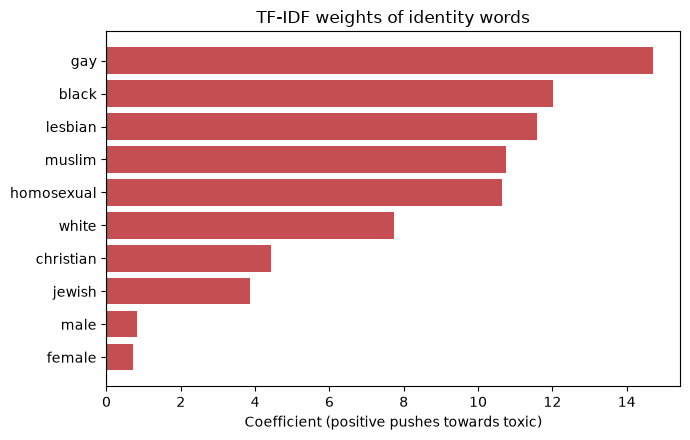

In [12]:
colors = ["#C44E52" if w > 0 else "#4C72B0" for w in word_weights]

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(word_weights.index, word_weights.values, color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Coefficient (positive pushes towards toxic)")
ax.set_title("TF-IDF weights of identity words")
plt.tight_layout()
plt.show()



- All identity words have **positive weights**, so they increase the model's score and push the predicted probability towards 1 (toxic).

- The strongest are *gay*, *black* and *lesbian*. 

As a result, the model tends to associate comments that mention these identities with toxicity, and  neutral comments that mention them can be flagged even when they contain no insult.


## 4.4 Probe Sentences

In [13]:
probes = pd.read_csv("../data/probe_sentences.csv")

probes["prob toxic"] = final_clf.predict_proba(vectorizer.transform(probes["sentence"]))[:, 1].round(3)
probes["model result"] = (probes["prob toxic"] >= 0.5).map({True: "toxic", False: "non-toxic"})
probes = probes.rename(columns={"expected": "target"})
probes["correct"] = (probes["model result"] == probes["target"]).map({True: "yes", False: "no"})

for category, group in probes.groupby("category", sort=False):
    print(f"\n{category}")
    display(group[["sentence", "target", "prob toxic", "model result", "correct"]].reset_index(drop=True))



negation with insult


,sentence,target,prob toxic,model result,correct
0,You are an idiot,toxic,1.0,toxic,yes
1,You are not an idiot,non-toxic,1.0,toxic,no
2,You are stupid,toxic,1.0,toxic,yes
3,You are not stupid,non-toxic,1.0,toxic,no



negation without insult


,sentence,target,prob toxic,model result,correct
0,I hate gay people,toxic,0.994,toxic,yes
1,I don't hate gay people,non-toxic,0.934,toxic,no
2,Black people are criminals,toxic,0.999,toxic,yes
3,Black people are not criminals,non-toxic,0.839,toxic,no



identity mention


...

,sentence,target,prob toxic,model result,correct
0,Calling someone an idiot is not okay,non-toxic,1.000,toxic,no
1,Saying gay people are disgusting is hateful,non-toxic,0.999,toxic,no



profanity


,sentence,target,prob toxic,model result,correct
0,This movie is fucking amazing,non-toxic,1.0,toxic,no
1,Holy shit what a great game,non-toxic,1.0,toxic,no



word order


,sentence,target,prob toxic,model result,correct
0,You are an idiot and I am right,toxic,1.0,toxic,yes
1,I am an idiot and you are right,non-toxic,1.0,toxic,no


**Conclusions:**

- **Toxic sentences are detected:** all toxic probe sentences are flagged, unlike the blocklist, which detected none of them.

- **Negations are not understood:** "You are not an idiot" and "You are not stupid" get a probability of 1.0, the same as without "not". In the identity sentences, bigrams such as *not criminals* lower the probability slightly , but not enough to change the decision.

- **Identity bias:** "My neighbor is black" is flagged while "My neighbor is tall" is not, and "I am a Muslim woman" is flagged.


 **No context or word order**

- **Why:** the model adds up the weights of the words and bigrams in the sentence. An insult or an identity word with a large weight dominates the sum, whatever surrounds it.


## 4.5 Most Influential Terms

Inspect the coefficients of the selected model: the terms with the largest positive weights push comments towards the toxic class, and identity terms with high weights point to bias.

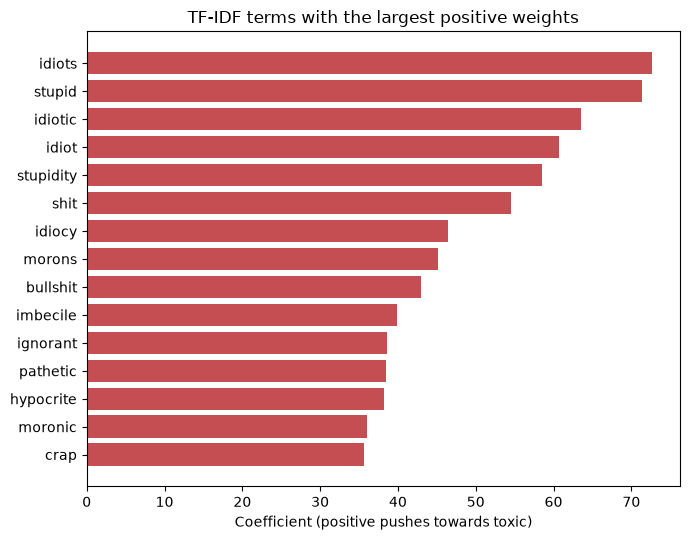

In [14]:
top15 = coefs.sort_values(ascending=False).head(15).iloc[::-1]   # largest at the top

fig, ax = plt.subplots(figsize=(7, 5.5))
ax.barh(top15.index, top15.values, color="#C44E52")
ax.set_xlabel("Coefficient (positive pushes towards toxic)")
ax.set_title("TF-IDF terms with the largest positive weights")
plt.tight_layout()
plt.show()


# 5. Saving Predictions and Model

Save the test predictions in `results/predictions/tfidf/` so that they can be compared with the other models, and the vectorizer and classifier in `models/tfidf_lr/` so that the same model can be applied to new sentences.

In [15]:


PRED_DIR = "../results/predictions/tfidf"

os.makedirs(PRED_DIR, exist_ok=True)
test[["id", "label", "prob_toxic", "pred"]].to_parquet(f"{PRED_DIR}/test.parquet", index=False)
print(f"Saved {len(test):,} predictions to {PRED_DIR}/test.parquet")


Saved 177,635 predictions to ../results/predictions/tfidf/test.parquet


In [16]:
import joblib

MODEL_DIR = "../models/tfidf_lr"

os.makedirs(MODEL_DIR, exist_ok=True)
joblib.dump(vectorizer, f"{MODEL_DIR}/vectorizer.joblib")
joblib.dump(final_clf, f"{MODEL_DIR}/classifier.joblib")
print(f"Saved vectorizer and classifier to {MODEL_DIR}")

Saved vectorizer and classifier to ../models/tfidf_lr
